# Exploratory data analysis

Week 2 - looking at the data before any modelling (CRISP-DM data understanding).

Things I want to check:
- distribution of num_orders
- trend / seasonality over the 145 weeks
- missing weeks in the centre-meal series
- which categories, centres and regions have the most orders
- effect of price and promotions
- autocorrelation (for lag features) and how noisy each series is

Figures are saved as png in `results/figures` at IEEE column size (settings in `src/plot_settings.py`).

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf

from src.plot_settings import set_ieee_style, save_fig, ONE_COL, TWO_COL

set_ieee_style()
pd.set_option('display.max_columns', 30)

## Load data

In [2]:
train = pd.read_csv('../data/raw/train.csv')
centers = pd.read_csv('../data/raw/fulfilment_center_info.csv')
meals = pd.read_csv('../data/raw/meal_info.csv')

df = train.merge(centers, on='center_id', how='left')
df = df.merge(meals, on='meal_id', how='left')
print(df.shape)
df.head()

(456548, 15)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,city_code,region_code,center_type,op_area,category,cuisine
0,1379560,1,55,1885,136.83,152.29,0,0,177,647,56,TYPE_C,2.0,Beverages,Thai
1,1466964,1,55,1993,136.83,135.83,0,0,270,647,56,TYPE_C,2.0,Beverages,Thai
2,1346989,1,55,2539,134.86,135.86,0,0,189,647,56,TYPE_C,2.0,Beverages,Thai
3,1338232,1,55,2139,339.50,437.53,0,0,54,647,56,TYPE_C,2.0,Beverages,Indian
4,1448490,1,55,2631,243.50,242.50,0,0,40,647,56,TYPE_C,2.0,Beverages,Indian


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 456548 entries, 0 to 456547
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id                     456548 non-null  int64  
 1   week                   456548 non-null  int64  
 2   center_id              456548 non-null  int64  
 3   meal_id                456548 non-null  int64  
 4   checkout_price         456548 non-null  float64
 5   base_price             456548 non-null  float64
 6   emailer_for_promotion  456548 non-null  int64  
 7   homepage_featured      456548 non-null  int64  
 8   num_orders             456548 non-null  int64  
 9   city_code              456548 non-null  int64  
 10  region_code            456548 non-null  int64  
 11  center_type            456548 non-null  str    
 12  op_area                456548 non-null  float64
 13  category               456548 non-null  str    
 14  cuisine                456548 non-null  str    

In [4]:
df.describe()

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,city_code,region_code,op_area
count,4.565480e+05,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.00000,456548.000000,456548.000000,456548.000000,456548.000000
mean,1.250096e+06,74.768771,82.105796,2024.337458,332.238933,354.156627,0.081152,0.10920,261.872760,601.553399,56.614566,4.083590
std,1.443548e+05,41.524956,45.975046,547.420920,152.939723,160.715914,0.273069,0.31189,395.922798,66.195914,17.641306,1.091686
min,1.000000e+06,1.000000,10.000000,1062.000000,2.970000,55.350000,0.000000,0.00000,13.000000,456.000000,23.000000,0.900000
25%,1.124999e+06,39.000000,43.000000,1558.000000,228.950000,243.500000,0.000000,0.00000,54.000000,553.000000,34.000000,3.600000
50%,1.250184e+06,76.000000,76.000000,1993.000000,296.820000,310.460000,0.000000,0.00000,136.000000,596.000000,56.000000,4.000000
75%,1.375140e+06,111.000000,110.000000,2539.000000,445.230000,458.870000,0.000000,0.00000,324.000000,651.000000,77.000000,4.500000
max,1.499999e+06,145.000000,186.000000,2956.000000,866.270000,866.270000,1.000000,1.00000,24299.000000,713.000000,93.000000,7.000000


In [5]:
# extra columns for the plots
df['discount'] = (df['base_price'] - df['checkout_price']) / df['base_price'] * 100
df['log_orders'] = np.log1p(df['num_orders'])

## 1. num_orders (target)

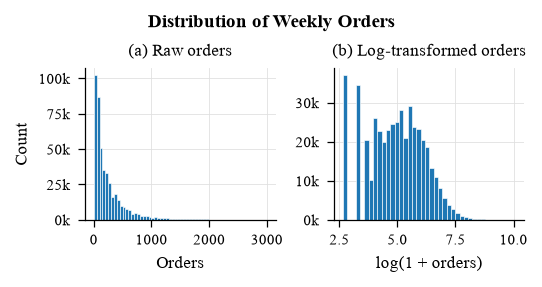

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(ONE_COL, 1.8))
fig.suptitle('Distribution of Weekly Orders')

ax[0].hist(df['num_orders'], bins=60, range=(0, 3000), color='tab:blue', edgecolor='white', linewidth=0.3)
ax[0].set_title('(a) Raw orders', fontweight='normal')
ax[0].set_xlabel('Orders')
ax[0].set_ylabel('Count')
ax[0].yaxis.set_major_formatter(lambda x, pos: f'{x/1000:.0f}k')

ax[1].hist(df['log_orders'], bins=40, color='tab:blue', edgecolor='white', linewidth=0.3)
ax[1].set_title('(b) Log-transformed orders', fontweight='normal')
ax[1].set_xlabel('log(1 + orders)')
ax[1].yaxis.set_major_formatter(lambda x, pos: f'{x/1000:.0f}k')

save_fig(fig, 'fig01_target_distribution')
plt.show()

In [7]:
print('skewness before log:', round(df['num_orders'].skew(), 2))
print('skewness after log:', round(df['log_orders'].skew(), 2))

skewness before log: 6.93
skewness after log: -0.02


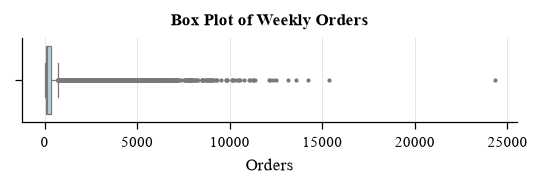

In [8]:
fig, ax = plt.subplots(figsize=(ONE_COL, 1.15))
sns.boxplot(x=df['num_orders'], ax=ax, color='lightblue', linewidth=0.6, fliersize=1)
ax.set_title('Box Plot of Weekly Orders')
ax.set_xlabel('Orders')
save_fig(fig, 'fig02_target_boxplot')
plt.show()

In [9]:
# biggest values
cols = ['week', 'center_id', 'meal_id', 'category', 'num_orders', 'checkout_price', 'emailer_for_promotion', 'homepage_featured']
df.sort_values('num_orders', ascending=False)[cols].head(10)

,week,center_id,meal_id,category,num_orders,checkout_price,emailer_for_promotion,homepage_featured
14050,5,43,2290,Rice Bowl,24299,159.08,1,1
19700,7,43,2290,Rice Bowl,15336,159.08,1,1
16904,6,43,2290,Rice Bowl,14229,156.20,0,1
13923,5,10,2290,Rice Bowl,13580,162.99,1,0
413351,132,43,1971,Sandwich,13150,204.70,1,1
12068,5,89,2290,Rice Bowl,12489,162.02,1,1
90857,32,146,1754,Sandwich,12327,194.03,1,1
12509,5,137,2290,Rice Bowl,12177,159.11,1,1
12300,5,99,2290,Rice Bowl,12137,162.02,1,1
85371,30,126,1754,Sandwich,11380,144.56,1,1


In [10]:
q1 = df['num_orders'].quantile(0.25)
q3 = df['num_orders'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
n_out = (df['num_orders'] > upper).sum()
print('upper limit:', upper)
print('rows above limit:', n_out, '(' + str(round(n_out / len(df) * 100, 1)) + '%)')

upper limit: 729.0
rows above limit: 32937 (7.2%)


Target is very skewed (skewness 6.9), after log1p it is about 0, so I will train on the log scale.

About 7% of rows are outliers by the IQR rule, but they are just the big centres / popular meals, so I'm keeping them.
The max value (24,299) is centre 43, meal 2290 (Rice Bowl) in week 5. The same meal is also very high in weeks 6 and 7
and at centre 10, so it looks like a real event (probably a promotion) and not a typing mistake.
Panda and Mohanty removed this row - I will keep it for now.

## 2. Orders over time

In [11]:
weekly = df.groupby('week')['num_orders'].sum() / 1000
print('highest week:', weekly.idxmax(), ' lowest week:', weekly.idxmin())

highest week: 48  lowest week: 62


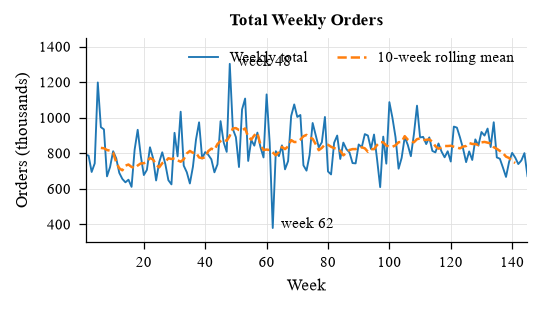

In [12]:
fig, ax = plt.subplots(figsize=(ONE_COL, 1.95))
ax.plot(weekly, color='tab:blue', linewidth=0.9, label='Weekly total')
ax.plot(weekly.rolling(10, center=True).mean(), color='tab:orange', linestyle='--', linewidth=1.2, label='10-week rolling mean')
ax.annotate('week 48', (48, weekly[48]), xytext=(4, -1), textcoords='offset points', fontsize=7)
ax.annotate('week 62', (62, weekly[62]), xytext=(4, 0), textcoords='offset points', fontsize=7)
ax.set_title('Total Weekly Orders')
ax.set_xlabel('Week')
ax.set_ylabel('Orders (thousands)')
ax.set_xlim(1, 145)
ax.set_ylim(300, 1450)
ax.legend(ncol=2, loc='upper right')
save_fig(fig, 'fig03_weekly_total')
plt.show()

In [13]:
cat_weekly = df.pivot_table(index='week', columns='category', values='num_orders', aggfunc='sum') / 1000
cat_weekly.sum().sort_values(ascending=False)

category
Beverages       40480.525
Rice Bowl       20874.063
Sandwich        17636.782
Salad           10944.336
Pizza            7383.720
Other Snacks     4766.293
Starters         4649.122
Extras           3984.979
Seafood          2715.714
Desert           1940.754
Pasta            1637.744
Soup             1039.646
Fish              871.959
Biryani           631.848
dtype: float64

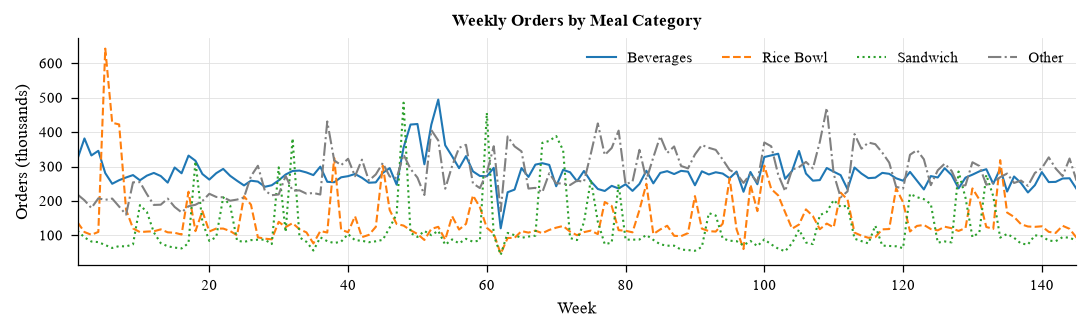

In [14]:
# 14 categories in one plot is unreadable, so top 3 + other
top3 = ['Beverages', 'Rice Bowl', 'Sandwich']
cat_weekly['Other'] = cat_weekly.drop(columns=top3).sum(axis=1)

fig, ax = plt.subplots(figsize=(TWO_COL, 2.1))
ax.plot(cat_weekly['Beverages'], color='tab:blue', label='Beverages')
ax.plot(cat_weekly['Rice Bowl'], color='tab:orange', linestyle='--', label='Rice Bowl')
ax.plot(cat_weekly['Sandwich'], color='tab:green', linestyle=':', label='Sandwich')
ax.plot(cat_weekly['Other'], color='grey', linestyle='-.', label='Other')
ax.set_title('Weekly Orders by Meal Category')
ax.set_xlabel('Week')
ax.set_ylabel('Orders (thousands)')
ax.set_xlim(1, 145)
ax.legend(ncol=4, loc='upper right')
save_fig(fig, 'fig04_weekly_by_category')
plt.show()

No real long term trend, but lots of spikes (week 48 highest, week 62 lowest). The category plot shows the spikes
usually come from one category at a time, e.g. Rice Bowl in week 5 and Sandwich around weeks 48 and 60.
Probably promotions.

### Autocorrelation

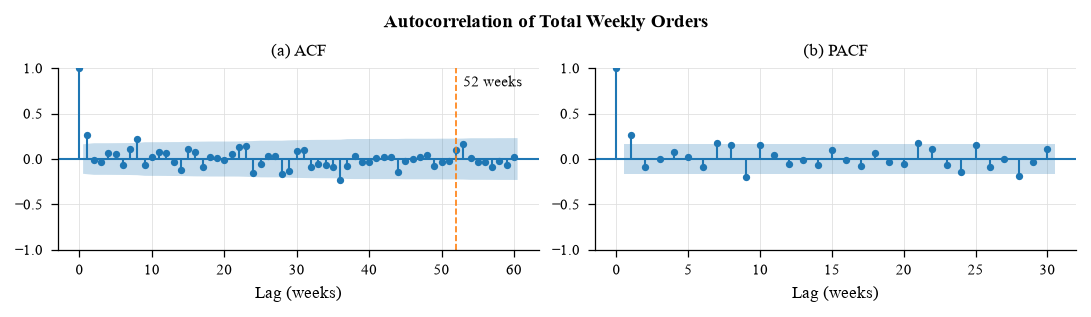

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(TWO_COL, 2.0))
fig.suptitle('Autocorrelation of Total Weekly Orders')

plot_acf(weekly, lags=60, ax=ax[0], title='', markersize=2.5)
ax[0].axvline(52, color='tab:orange', linestyle='--', linewidth=0.8)
ax[0].text(53, 0.8, '52 weeks', fontsize=7)
ax[0].set_title('(a) ACF', fontweight='normal')
ax[0].set_xlabel('Lag (weeks)')

plot_pacf(weekly, lags=30, ax=ax[1], title='', markersize=2.5, method='ywm')
ax[1].set_title('(b) PACF', fontweight='normal')
ax[1].set_xlabel('Lag (weeks)')

save_fig(fig, 'fig05_acf_pacf_total')
plt.show()

In [16]:
# acf for each centre-meal series (only series with at least 100 weeks)
# missing weeks are interpolated just for this calculation
pivot = df.pivot_table(index='week', columns=['center_id', 'meal_id'], values='log_orders')
pivot = pivot.loc[:, pivot.count() >= 100]

acf_values = []
for col in pivot.columns:
    s = pivot[col].interpolate().dropna()
    acf_values.append(acf(s, nlags=20))
acf_values = np.array(acf_values)
print(acf_values.shape)

(3109, 21)


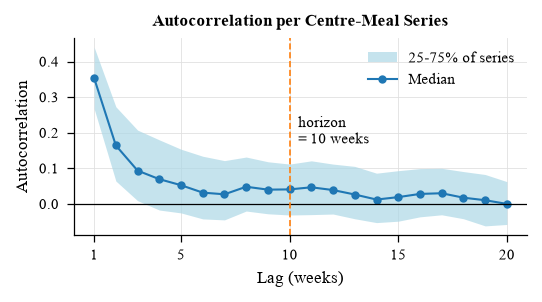

median acf lag 1: 0.35
median acf lag 10: 0.04


In [17]:
med = np.nanmedian(acf_values, axis=0)
q25 = np.nanpercentile(acf_values, 25, axis=0)
q75 = np.nanpercentile(acf_values, 75, axis=0)
lags = np.arange(1, 21)

fig, ax = plt.subplots(figsize=(ONE_COL, 1.9))
ax.fill_between(lags, q25[1:], q75[1:], color='lightblue', alpha=0.7, linewidth=0, label='25-75% of series')
ax.plot(lags, med[1:], color='tab:blue', marker='o', markersize=3, label='Median')
ax.axhline(0, color='black', linewidth=0.6)
ax.axvline(10, color='tab:orange', linestyle='--', linewidth=0.8)
ax.text(10.4, 0.25, 'horizon\n= 10 weeks', fontsize=7, va='top')
ax.set_title('Autocorrelation per Centre-Meal Series')
ax.set_xlabel('Lag (weeks)')
ax.set_ylabel('Autocorrelation')
ax.set_xticks([1, 5, 10, 15, 20])
ax.legend(loc='upper right')
save_fig(fig, 'fig06_acf_per_series')
plt.show()

print('median acf lag 1:', round(med[1], 2))
print('median acf lag 10:', round(med[10], 2))

For the total there is a small spike at lag 1 and nothing at 52 weeks, so no yearly seasonality to model.

Per series the median ACF is 0.35 at lag 1 but only 0.04 at lag 10. This is important: we forecast up to 10 weeks
ahead, and lags 1-9 are not known at the forecast origin (using them would be leakage). So for the long horizon,
past orders don't help much and price / promotion / the recent average level will be more useful.

## 3. Missing weeks

In [18]:
n_series = df.groupby(['center_id', 'meal_id']).ngroups
print('series:', n_series)
print('possible rows:', n_series * 145)
print('actual rows:', len(df))
print('missing:', n_series * 145 - len(df))

series: 3597
possible rows: 521565
actual rows: 456548
missing: 65017


In [19]:
# where are the missing weeks? before the series starts, gaps in the middle, or after it ends
s = df.groupby(['center_id', 'meal_id'])['week'].agg(['min', 'max', 'count'])
s['before'] = s['min'] - 1
s['after'] = 145 - s['max']
s['gaps'] = (s['max'] - s['min'] + 1) - s['count']

print(s[['before', 'gaps', 'after']].sum())
print('series without gaps:', (s['gaps'] == 0).sum())
print('series with all 145 weeks:', (s['count'] == 145).sum())

before    21468
gaps      40548
after      3001
dtype: int64
series without gaps: 1468
series with all 145 weeks: 1247


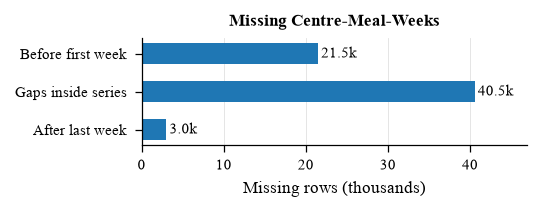

In [20]:
missing = s[['after', 'gaps', 'before']].sum() / 1000

fig, ax = plt.subplots(figsize=(ONE_COL, 1.3))
ax.barh(['After last week', 'Gaps inside series', 'Before first week'], missing.values, color='tab:blue', height=0.55)
for i, v in enumerate(missing.values):
    ax.text(v + 0.4, i, f'{v:.1f}k', va='center', fontsize=7)
ax.set_title('Missing Centre-Meal-Weeks')
ax.set_xlabel('Missing rows (thousands)')
ax.set_xlim(0, 47)
ax.grid(axis='y', visible=False)
save_fig(fig, 'fig07_missing_breakdown')
plt.show()

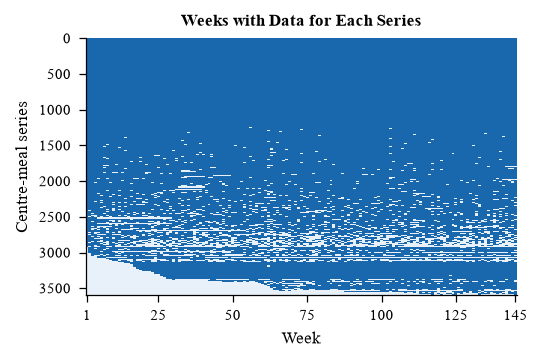

In [21]:
# 1 if the series has a row in that week. sorted by first week so the late starters are at the bottom
present = df.pivot_table(index=['center_id', 'meal_id'], columns='week', values='num_orders', aggfunc='count', fill_value=0)
present = present.loc[s.sort_values(['min', 'count'], ascending=[True, False]).index]

fig, ax = plt.subplots(figsize=(ONE_COL, 2.3))
ax.imshow(present > 0, aspect='auto', cmap='Blues', vmin=-0.1, vmax=1.3, interpolation='nearest',
          extent=[0.5, 145.5, len(present), 0])
ax.set_title('Weeks with Data for Each Series')
ax.set_xlabel('Week')
ax.set_ylabel('Centre-meal series')
ax.set_xticks([1, 25, 50, 75, 100, 125, 145])
ax.grid(False)
save_fig(fig, 'fig08_presence_map')
plt.show()

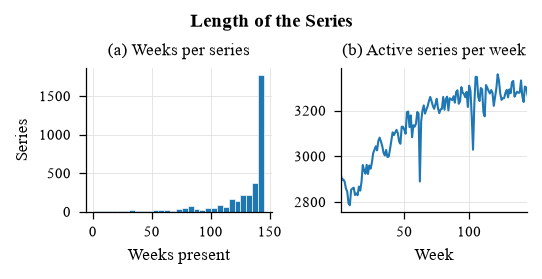

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(ONE_COL, 1.75))
fig.suptitle('Length of the Series')

ax[0].hist(s['count'], bins=29, color='tab:blue', edgecolor='white', linewidth=0.3)
ax[0].set_title('(a) Weeks per series', fontweight='normal')
ax[0].set_xlabel('Weeks present')
ax[0].set_ylabel('Series')

ax[1].plot(present.sum(axis=0), color='tab:blue')
ax[1].set_title('(b) Active series per week', fontweight='normal')
ax[1].set_xlabel('Week')
ax[1].set_xlim(1, 145)

save_fig(fig, 'fig09_series_length')
plt.show()

65,017 rows are missing. 21,468 are before the series starts and 3,001 after it ends (meal not on the menu yet / any more),
but most of them (40,548) are gaps in the middle of a series. Only 1,468 of the 3,597 series have no gaps at all.

The smallest num_orders in the data is 13, so there are no zero weeks. I think a gap means the meal was not offered
(or not recorded) that week, not that demand was zero. So:
- don't fill the gaps with 0
- leave these weeks out of the waste / shortage simulation
- lag features have to be made using the week number, not the row before (otherwise "lag 1" can be several weeks back)

## 4. Categories, cuisines, centres and regions

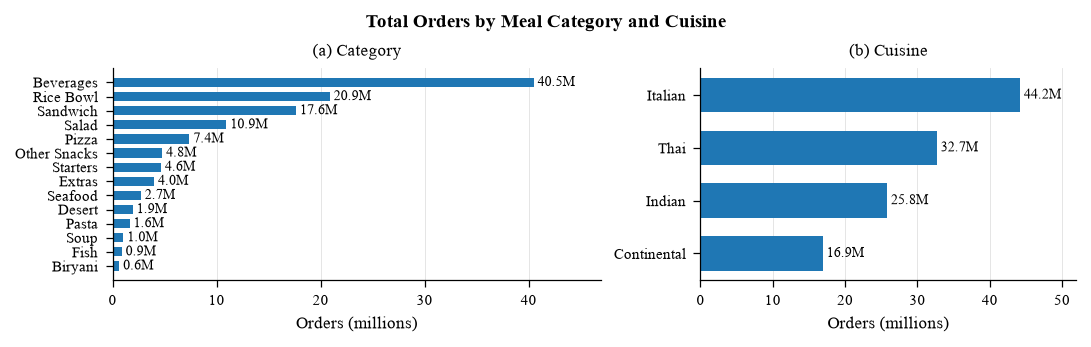

In [23]:
cat_total = df.groupby('category')['num_orders'].sum().sort_values() / 1e6
cuisine_total = df.groupby('cuisine')['num_orders'].sum().sort_values() / 1e6

fig, ax = plt.subplots(1, 2, figsize=(TWO_COL, 2.2), width_ratios=[1.3, 1])
fig.suptitle('Total Orders by Meal Category and Cuisine')

ax[0].barh(cat_total.index, cat_total.values, color='tab:blue', height=0.65)
for i, v in enumerate(cat_total.values):
    ax[0].text(v, i, f' {v:.1f}M', va='center', fontsize=6.5)
ax[0].set_title('(a) Category', fontweight='normal')
ax[0].set_xlabel('Orders (millions)')
ax[0].set_xlim(0, 47)
ax[0].grid(axis='y', visible=False)

ax[1].barh(cuisine_total.index, cuisine_total.values, color='tab:blue', height=0.65)
for i, v in enumerate(cuisine_total.values):
    ax[1].text(v, i, f' {v:.1f}M', va='center', fontsize=6.5)
ax[1].set_title('(b) Cuisine', fontweight='normal')
ax[1].set_xlabel('Orders (millions)')
ax[1].set_xlim(0, 52)
ax[1].grid(axis='y', visible=False)

save_fig(fig, 'fig10_orders_category_cuisine')
plt.show()

In [24]:
centers['center_type'].value_counts()

center_type
TYPE_A    43
TYPE_C    19
TYPE_B    15
Name: count, dtype: int64

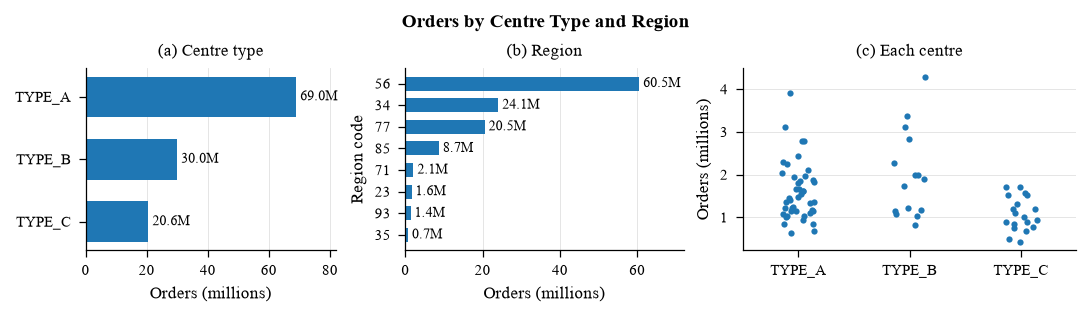

In [25]:
type_total = df.groupby('center_type')['num_orders'].sum().sort_values() / 1e6
region_total = df.groupby('region_code')['num_orders'].sum().sort_values() / 1e6
center_total = df.groupby(['center_id', 'center_type'])['num_orders'].sum().reset_index()
center_total['num_orders'] = center_total['num_orders'] / 1e6

fig, ax = plt.subplots(1, 3, figsize=(TWO_COL, 2.0), width_ratios=[0.9, 1, 1.2])
fig.suptitle('Orders by Centre Type and Region')

ax[0].barh(type_total.index, type_total.values, color='tab:blue', height=0.65)
for i, v in enumerate(type_total.values):
    ax[0].text(v, i, f' {v:.1f}M', va='center', fontsize=6.5)
ax[0].set_title('(a) Centre type', fontweight='normal')
ax[0].set_xlabel('Orders (millions)')
ax[0].set_xlim(0, 82)
ax[0].grid(axis='y', visible=False)

ax[1].barh(region_total.index.astype(str), region_total.values, color='tab:blue', height=0.65)
for i, v in enumerate(region_total.values):
    ax[1].text(v, i, f' {v:.1f}M', va='center', fontsize=6.5)
ax[1].set_title('(b) Region', fontweight='normal')
ax[1].set_xlabel('Orders (millions)')
ax[1].set_ylabel('Region code')
ax[1].set_xlim(0, 72)
ax[1].grid(axis='y', visible=False)

sns.stripplot(data=center_total, x='center_type', y='num_orders', order=['TYPE_A', 'TYPE_B', 'TYPE_C'],
              color='tab:blue', size=3, jitter=0.15, ax=ax[2])
ax[2].set_title('(c) Each centre', fontweight='normal')
ax[2].set_xlabel('')
ax[2].set_ylabel('Orders (millions)')
ax[2].grid(axis='x', visible=False)

save_fig(fig, 'fig11_orders_centres_regions')
plt.show()

correlation: 0.73


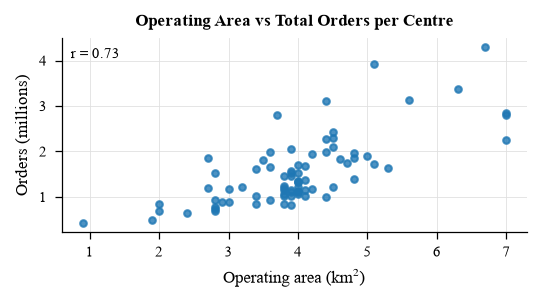

In [26]:
area = centers.set_index('center_id')['op_area']
orders_per_center = df.groupby('center_id')['num_orders'].sum() / 1e6
r = np.corrcoef(area[orders_per_center.index], orders_per_center)[0, 1]
print('correlation:', round(r, 2))

fig, ax = plt.subplots(figsize=(ONE_COL, 1.9))
ax.scatter(area[orders_per_center.index], orders_per_center, color='tab:blue', s=10, alpha=0.8)
ax.text(0.02, 0.95, f'r = {r:.2f}', transform=ax.transAxes, fontsize=7, va='top')
ax.set_title('Operating Area vs Total Orders per Centre')
ax.set_xlabel('Operating area (km$^2$)')
ax.set_ylabel('Orders (millions)')
save_fig(fig, 'fig12_op_area_vs_orders')
plt.show()

Beverages is by far the biggest category. Type A has the most orders, but that is because there are 43 type A centres
(only 15 type B), per centre type B is actually bigger. Region 56 has half of all orders. Bigger operating area
-> more orders (r = 0.73), so centre features should be kept in the model.

## 5. Price, discount and promotions

Too many rows for a normal scatter plot so I used hexbin.

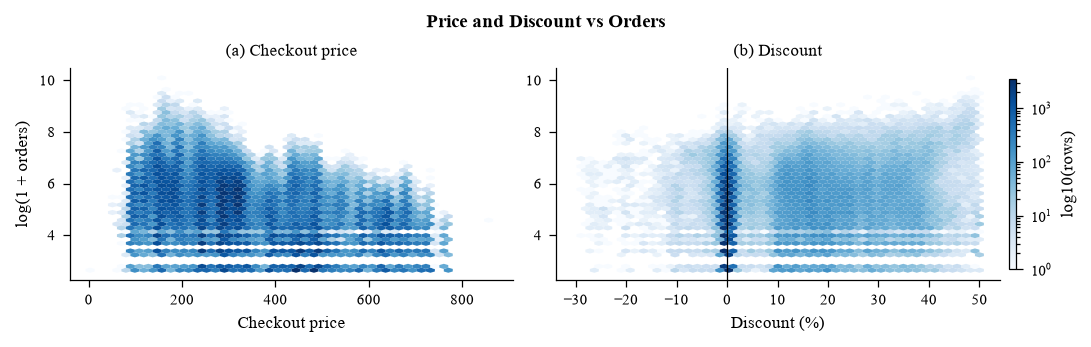

rows where checkout price > base price: 116101


In [27]:
d = df[(df['discount'] > -30) & (df['discount'] < 50)]

fig, ax = plt.subplots(1, 2, figsize=(TWO_COL, 2.2))
fig.suptitle('Price and Discount vs Orders')

hb = ax[0].hexbin(df['checkout_price'], df['log_orders'], gridsize=45, cmap='Blues', bins='log', mincnt=1, linewidths=0)
ax[0].set_title('(a) Checkout price', fontweight='normal')
ax[0].set_xlabel('Checkout price')
ax[0].set_ylabel('log(1 + orders)')
ax[0].grid(False)

ax[1].hexbin(d['discount'], d['log_orders'], gridsize=45, cmap='Blues', bins='log', mincnt=1, linewidths=0)
ax[1].axvline(0, color='black', linewidth=0.6)
ax[1].set_title('(b) Discount', fontweight='normal')
ax[1].set_xlabel('Discount (%)')
ax[1].grid(False)

cb = fig.colorbar(hb, ax=ax, shrink=0.9, pad=0.01, aspect=25)
cb.set_label('log10(rows)')
save_fig(fig, 'fig13_price_discount_hexbin')
plt.show()

print('rows where checkout price > base price:', (df['discount'] < 0).sum())

In [28]:
# the plot above mixes cheap and expensive meals. better to compare each week with the same series' average
df['price_change'] = (df['checkout_price'] / df.groupby(['center_id', 'meal_id'])['checkout_price'].transform('mean') - 1) * 100
df['orders_change'] = df['log_orders'] - df.groupby(['center_id', 'meal_id'])['log_orders'].transform('mean')

df['price_bin'] = pd.cut(df['price_change'], bins=range(-30, 31, 5))
price_effect = df.groupby('price_bin', observed=True)['orders_change'].mean()
price_effect

price_bin
(-30, -25]    0.904332
(-25, -20]    0.773035
(-20, -15]    0.509337
(-15, -10]    0.259361
(-10, -5]     0.128938
(-5, 0]      -0.006654
(0, 5]       -0.080081
(5, 10]      -0.164499
(10, 15]     -0.338375
(15, 20]     -0.405822
(20, 25]     -0.551431
(25, 30]     -0.506899
Name: orders_change, dtype: float64

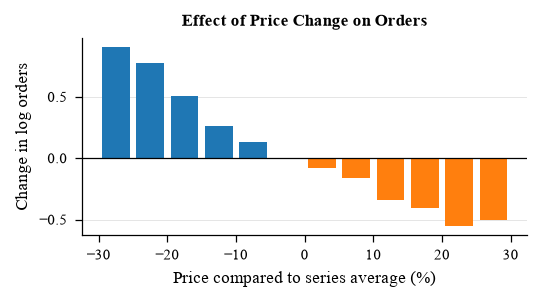

In [29]:
x = [b.mid for b in price_effect.index]
colors = ['tab:blue' if v > 0 else 'tab:orange' for v in price_effect.values]

fig, ax = plt.subplots(figsize=(ONE_COL, 1.9))
ax.bar(x, price_effect.values, width=4, color=colors)
ax.axhline(0, color='black', linewidth=0.6)
ax.set_title('Effect of Price Change on Orders')
ax.set_xlabel('Price compared to series average (%)')
ax.set_ylabel('Change in log orders')
ax.grid(axis='x', visible=False)
save_fig(fig, 'fig14_price_effect_within_series')
plt.show()

In [30]:
df['promo'] = 'None'
df.loc[df['emailer_for_promotion'] == 1, 'promo'] = 'Email'
df.loc[df['homepage_featured'] == 1, 'promo'] = 'Homepage'
df.loc[(df['emailer_for_promotion'] == 1) & (df['homepage_featured'] == 1), 'promo'] = 'Both'
df['promo'].value_counts()

promo
None        388874
Homepage     30624
Both         19231
Email        17819
Name: count, dtype: int64

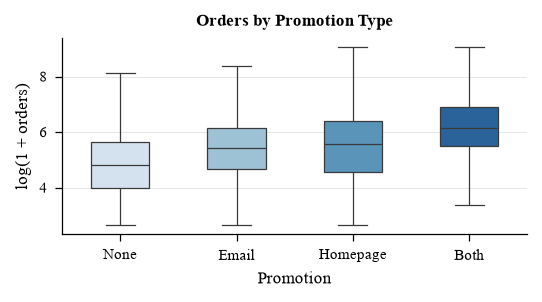

promo
Both        474.0
Email       229.0
Homepage    258.0
None        122.0
Name: num_orders, dtype: float64

In [31]:
fig, ax = plt.subplots(figsize=(ONE_COL, 1.9))
promo_order = ['None', 'Email', 'Homepage', 'Both']
sns.boxplot(data=df, x='promo', y='log_orders', order=promo_order,
            hue='promo', hue_order=promo_order, palette='Blues', legend=False, showfliers=False, linewidth=0.6, width=0.5, ax=ax)
ax.set_title('Orders by Promotion Type')
ax.set_xlabel('Promotion')
ax.set_ylabel('log(1 + orders)')
save_fig(fig, 'fig15_promotion_boxplot')
plt.show()

df.groupby('promo')['num_orders'].median()

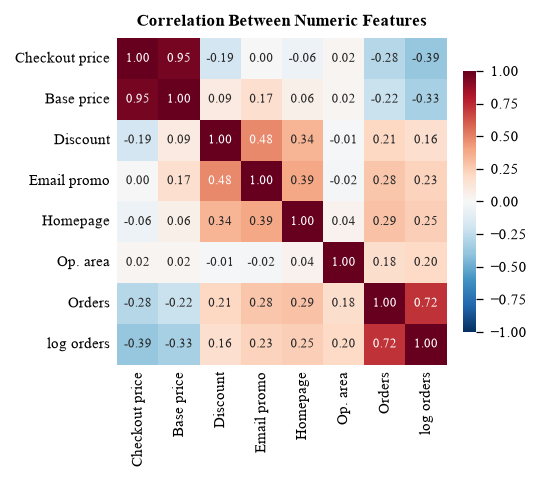

In [32]:
corr_cols = ['checkout_price', 'base_price', 'discount', 'emailer_for_promotion', 'homepage_featured', 'op_area', 'num_orders', 'log_orders']
names = ['Checkout price', 'Base price', 'Discount', 'Email promo', 'Homepage', 'Op. area', 'Orders', 'log orders']
corr = df[corr_cols].corr()
corr.index = names
corr.columns = names

fig, ax = plt.subplots(figsize=(ONE_COL, 3.1))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, annot_kws={'size': 6},
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlation Between Numeric Features')
ax.tick_params(length=0)
save_fig(fig, 'fig16_correlation_heatmap')
plt.show()

Within a series, a lower price than usual clearly gives more orders (30% cheaper -> about +0.9 in log orders) and
a higher price gives fewer. Promotions have a big effect: median orders are 122 without promotion, 229 with email,
258 with homepage and 474 with both. So price change and the promo flags will be important features.

checkout_price and base_price are 0.95 correlated so I'll use one price plus the discount instead of both.
116k rows have checkout price higher than base price (the dataset says checkout includes taxes / delivery) so
negative discount is fine.

## 6. How noisy are the series?

Coefficient of variation = std / mean for each series (at least 20 weeks).
If series are very noisy a normal (mean) forecast will often be wrong, and then it matters whether we
over or under forecast - this is the reason for trying quantile regression.

In [33]:
cv = df.groupby(['center_id', 'meal_id'])['num_orders'].agg(['mean', 'std', 'count'])
cv = cv[cv['count'] >= 20]
cv['cv'] = cv['std'] / cv['mean']
cv['cv'].describe()

count    3556.000000
mean        0.690342
std         0.269188
min         0.056233
25%         0.505559
50%         0.631539
75%         0.844769
max         2.145306
Name: cv, dtype: float64

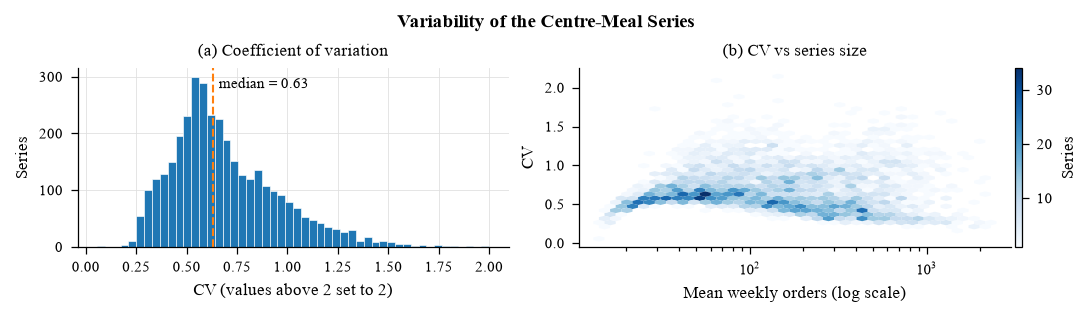

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(TWO_COL, 2.0))
fig.suptitle('Variability of the Centre-Meal Series')

ax[0].hist(cv['cv'].clip(upper=2), bins=50, color='tab:blue', edgecolor='white', linewidth=0.3)
ax[0].axvline(cv['cv'].median(), color='tab:orange', linestyle='--')
ax[0].text(0.66, 280, 'median = ' + str(round(cv['cv'].median(), 2)), fontsize=7)
ax[0].set_title('(a) Coefficient of variation', fontweight='normal')
ax[0].set_xlabel('CV (values above 2 set to 2)')
ax[0].set_ylabel('Series')

hb = ax[1].hexbin(cv['mean'], cv['cv'], gridsize=35, cmap='Blues', xscale='log', mincnt=1, linewidths=0)
ax[1].set_title('(b) CV vs series size', fontweight='normal')
ax[1].set_xlabel('Mean weekly orders (log scale)')
ax[1].set_ylabel('CV')
ax[1].grid(False)
fig.colorbar(hb, ax=ax[1], pad=0.01, aspect=25, label='Series')

save_fig(fig, 'fig17_volatility')
plt.show()

In [35]:
# looking for some example series to plot
cv[cv['count'] == 145].sort_values('mean', ascending=False).head(10)

mean          std  count        cv
center_id meal_id                                           
13        1885     2305.751724   561.276342    145  0.243424
          2290     2204.662069  1387.127414    145  0.629179
174       1885     2143.972414   444.316562    145  0.207240
43        2290     2129.406897  2805.994081    145  1.317735
13        2707     2061.551724   558.640760    145  0.270981
157       1885     2010.958621  1719.740601    145  0.855184
13        1993     1982.117241   472.762442    145  0.238514
43        1885     1981.248276   385.313897    145  0.194480
10        2290     1910.234483  1514.622294    145  0.792899
67        1885     1865.806897   357.384272    145  0.191544

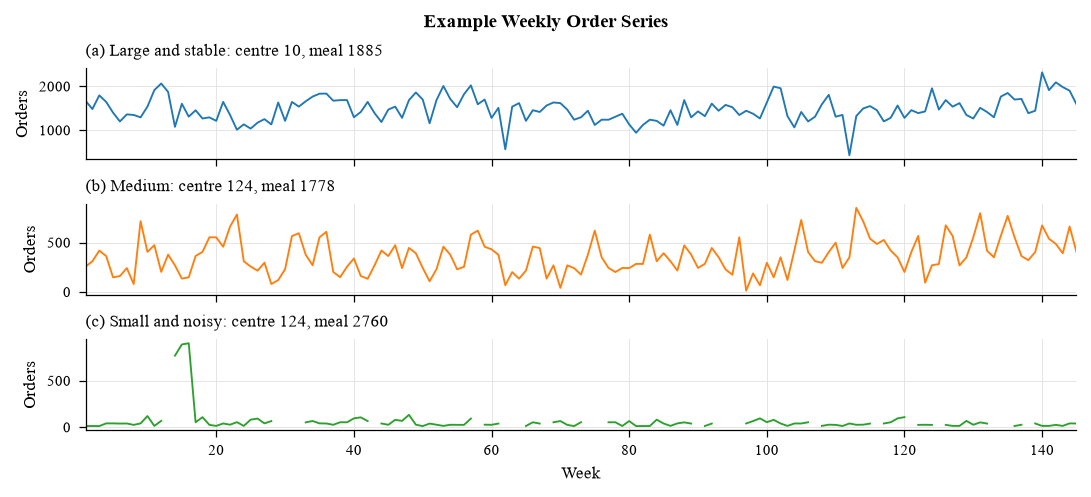

In [36]:
# picked after looking at the cv table: one big + stable, one medium, one small + noisy
examples = [(10, 1885, '(a) Large and stable'), (124, 1778, '(b) Medium'), (124, 2760, '(c) Small and noisy')]
colors = ['tab:blue', 'tab:orange', 'tab:green']

fig, ax = plt.subplots(3, 1, figsize=(TWO_COL, 3.2), sharex=True)
fig.suptitle('Example Weekly Order Series')

for i in range(3):
    center, meal, label = examples[i]
    series = df[(df['center_id'] == center) & (df['meal_id'] == meal)].set_index('week')['num_orders']
    series = series.reindex(range(1, 146))   # so missing weeks show as gaps
    ax[i].plot(series, color=colors[i], linewidth=0.9)
    ax[i].set_title(f'{label}: centre {center}, meal {meal}', fontweight='normal', loc='left')
    ax[i].set_ylabel('Orders')

ax[2].set_xlabel('Week')
ax[2].set_xlim(1, 145)
save_fig(fig, 'fig18_example_series')
plt.show()

Median CV is 0.63 so most series are quite noisy, and the small series are the noisiest. The example in (c) also
shows the gaps and a sudden jump around week 14-16.

## 7. Validation folds

Not really EDA but I need this figure for the methodology section. Rolling origin: train on everything before,
test on the next 10 weeks, then move forward 10 weeks.

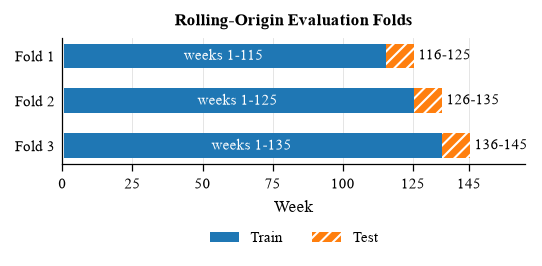

In [37]:
folds = [(115, 125), (125, 135), (135, 145)]

fig, ax = plt.subplots(figsize=(ONE_COL, 1.5))
for i in range(3):
    train_end, test_end = folds[i]
    y = 3 - i
    ax.barh(y, train_end, left=0.5, color='tab:blue', height=0.55, label='Train' if i == 0 else None)
    ax.barh(y, test_end - train_end, left=train_end + 0.5, color='tab:orange', hatch='////', edgecolor='white',
            linewidth=0, height=0.55, label='Test' if i == 0 else None)
    ax.text(train_end / 2, y, f'weeks 1-{train_end}', color='white', ha='center', va='center', fontsize=7)
    ax.text(test_end + 2, y, f'{train_end + 1}-{test_end}', va='center', fontsize=7)

ax.set_yticks([3, 2, 1])
ax.set_yticklabels(['Fold 1', 'Fold 2', 'Fold 3'])
ax.set_xlim(0, 165)
ax.set_xticks([0, 25, 50, 75, 100, 125, 145])
ax.set_title('Rolling-Origin Evaluation Folds')
ax.set_xlabel('Week')
ax.legend(ncol=2, loc='lower center', bbox_to_anchor=(0.5, -0.75))
ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', length=0)
save_fig(fig, 'fig19_rolling_origin_folds')
plt.show()

## Summary

- log transform the target, keep the large values (including the week 5 spike)
- no trend or yearly seasonality worth modelling
- autocorrelation drops to almost 0 by lag 10, and lags under 10 can't be used for a 10 week horizon
  -> rely more on price, promotions and recent average level
- 40k gaps inside series - not zero demand, leave them out of the simulation, build lags by week number
- price change and promotions have a strong effect on orders
- series are noisy (median CV 0.63), which supports using quantile forecasts instead of only the mean

Next: notebook 03, data preparation and features.